In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score,
    accuracy_score, precision_score, recall_score, f1_score
)

In [7]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(X.shape)
print(pd.Series(y).value_counts())

(569, 30)
1    357
0    212
Name: count, dtype: int64


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

[[41  1]
 [ 1 71]]


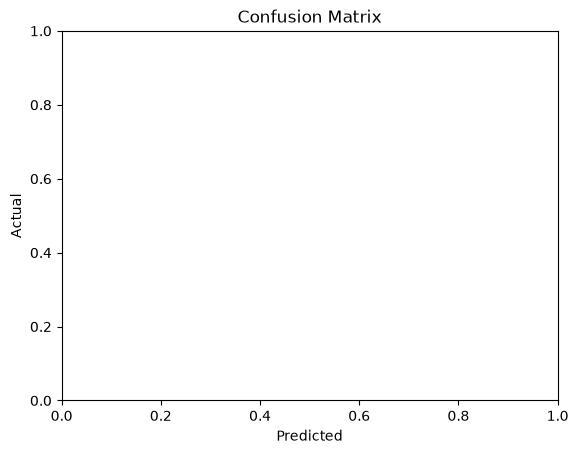

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [13]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=data.target_names))

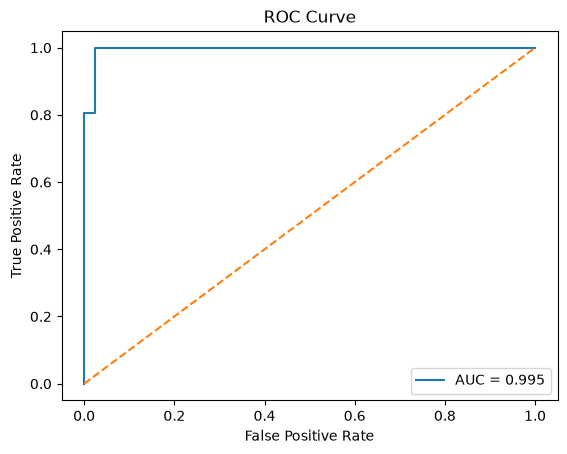

In [14]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [15]:
model_balanced = LogisticRegression(class_weight="balanced", max_iter=1000)
model_balanced.fit(X_train_scaled, y_train)
y_pred_bal = model_balanced.predict(X_test_scaled)
y_prob_bal = model_balanced.predict_proba(X_test_scaled)[:, 1]

print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal, target_names=data.target_names))

[[41  1]
 [ 4 68]]
              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



In [16]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)
y_prob_tree = tree.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_tree, target_names=data.target_names))
print("Train acc:", tree.score(X_train, y_train))
print("Test acc :", tree.score(X_test, y_test))

              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Train acc: 1.0
Test acc : 0.9122807017543859


In [17]:
def evaluate(name, yt, yp, ypr):
    return {
        "Model": name,
        "Accuracy": accuracy_score(yt, yp),
        "Precision": precision_score(yt, yp, pos_label=0),
        "Recall": recall_score(yt, yp, pos_label=0),
        "F1": f1_score(yt, yp, pos_label=0),
        "AUC": roc_auc_score(yt, ypr),
    }

results = pd.DataFrame([
    evaluate("LogReg baseline", y_test, y_pred, y_prob),
    evaluate("LogReg balanced", y_test, y_pred_bal, y_prob_bal),
    evaluate("Decision Tree", y_test, y_pred_tree, y_prob_tree),
]).round(3)
results

,Model,Accuracy,Precision,Recall,F1,AUC
0,LogReg baseline,0.982,0.976,0.976,0.976,0.995
1,LogReg balanced,0.956,0.911,0.976,0.943,0.995
2,Decision Tree,0.912,0.848,0.929,0.886,0.916


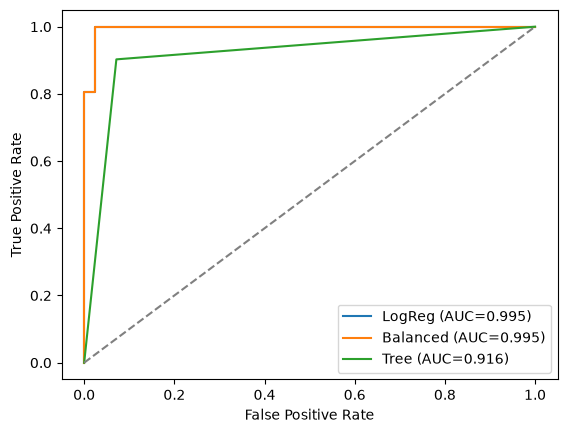

In [18]:
for name, p in [("LogReg", y_prob), ("Balanced", y_prob_bal), ("Tree", y_prob_tree)]:
    f, t, _ = roc_curve(y_test, p)
    plt.plot(f, t, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()